In [28]:
import seaborn as sns
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_iris 
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import pandas as pd


In [29]:
titanic = pd.read_csv("./Data/train.csv")

In [30]:
titanic.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [31]:
titanic["Cabin"].head()

0     NaN
1     C85
2     NaN
3    C123
4     NaN
Name: Cabin, dtype: object

In [32]:
titanic["Cabin"].value_counts()

B96 B98        4
G6             4
C23 C25 C27    4
C22 C26        3
F33            3
              ..
E34            1
C7             1
C54            1
E36            1
C148           1
Name: Cabin, Length: 147, dtype: int64

In [33]:
titanic["Embarked"].head()

0    S
1    C
2    S
3    S
4    S
Name: Embarked, dtype: object

In [34]:
titanic_df = pd.DataFrame(titanic)
titanic_df["Age"] = titanic_df["Age"].fillna(titanic_df["Age"].mean())
titanic_df["Cabin"] = titanic_df["Cabin"].fillna("N")
titanic_df["Embarked"] = titanic_df["Embarked"].fillna("N")
titanic_df.isnull().sum()


PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Cabin          0
Embarked       0
dtype: int64

In [35]:
titanic["Sex"].value_counts()

male      577
female    314
Name: Sex, dtype: int64

In [36]:
titanic["Embarked"].value_counts()

S    644
C    168
Q     77
Name: Embarked, dtype: int64

In [37]:
titanic_df["Cabin"] = titanic_df["Cabin"].str[:1]
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,N,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,N,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,N,S


In [38]:
titanic_df.groupby(["Sex","Survived"])["Survived"].count()

Sex     Survived
female  0            81
        1           233
male    0           468
        1           109
Name: Survived, dtype: int64

<Axes: xlabel='Sex', ylabel='Survived'>

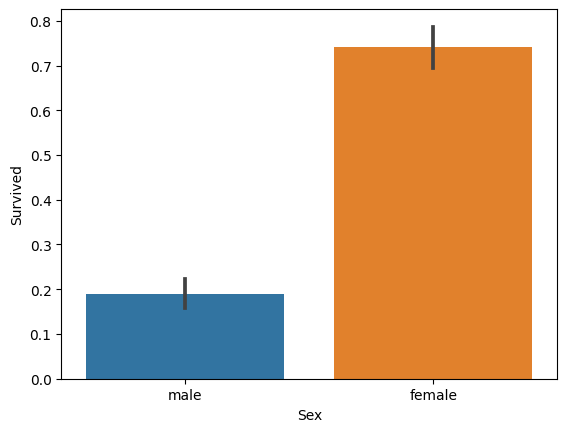

In [39]:
sns.barplot(x = "Sex", y = "Survived", data = titanic_df)

<Axes: xlabel='Pclass', ylabel='Survived'>

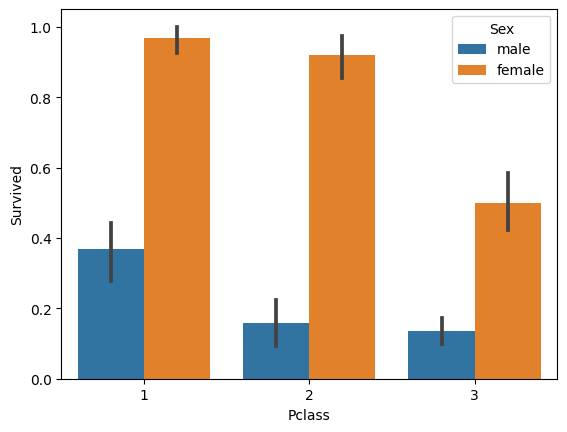

In [40]:
sns.barplot(x = "Pclass", y = "Survived",hue = "Sex", data = titanic_df)

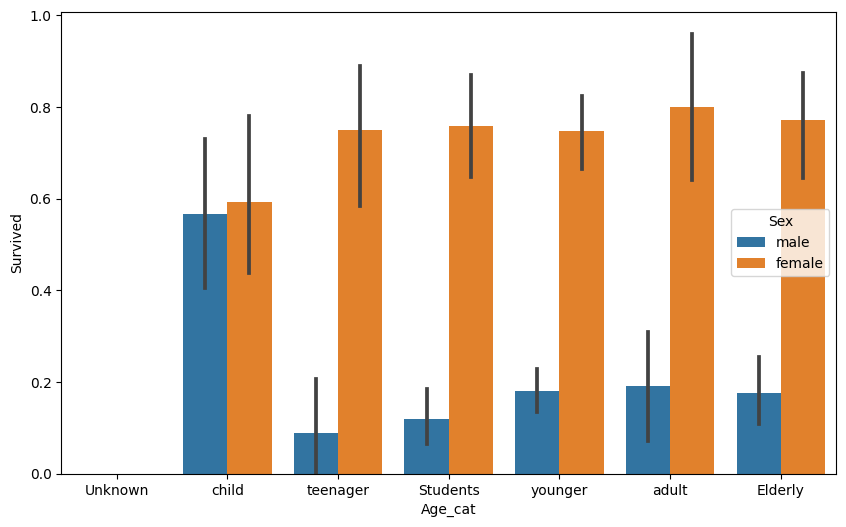

In [41]:
def get_category(age):
    cat = ""
    if age <= -1 : cat = "Unknown"
    elif age <= 12 : cat = "child"
    elif age <= 18 : cat = "teenager"
    elif age <= 25 : cat = "Students"
    elif age <= 35 : cat = "younger"
    elif age <= 40 : cat = "adult"
    else : cat = "Elderly"

    return cat


group_name = ["Unknown",
"child",
"teenager",
"Students",
"younger",
 "adult",
"Elderly"
]

titanic_df ["Age_cat"] = titanic_df["Age"].apply(lambda x : get_category(x))

plt.figure(figsize = (10,6))
sns.barplot(x = "Age_cat", y = "Survived", hue = "Sex",data = titanic_df,order = group_name)

titanic_df.drop("Age_cat", axis = 1 , inplace = True)



In [42]:
from sklearn import preprocessing

def encode_features(df):
    features = ["Cabin","Sex","Embarked"]
    for feature in features:
        le = preprocessing.LabelBinarizer()
        le = le.fit(df[feature])
        df[feature] = le.transform(df [ feature])

    return df

titanic_df = encode_features(titanic_df)
titanic_df


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.000000,1,0,A/5 21171,7.2500,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.000000,1,0,PC 17599,71.2833,0,1
2,3,1,3,"Heikkinen, Miss. Laina",0,26.000000,0,0,STON/O2. 3101282,7.9250,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.000000,1,0,113803,53.1000,0,0
4,5,0,3,"Allen, Mr. William Henry",1,35.000000,0,0,373450,8.0500,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",1,27.000000,0,0,211536,13.0000,0,0
887,888,1,1,"Graham, Miss. Margaret Edith",0,19.000000,0,0,112053,30.0000,0,0
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",0,29.699118,1,2,W./C. 6607,23.4500,0,0
889,890,1,1,"Behr, Mr. Karl Howell",1,26.000000,0,0,111369,30.0000,0,1


In [43]:
titanic_df["Sex"].value_counts()

1    577
0    314
Name: Sex, dtype: int64

In [44]:
titanic_df["Embarked"].value_counts()

0    723
1    168
Name: Embarked, dtype: int64

In [45]:
titanic_df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",1,22.0,1,0,A/5 21171,7.2500,0,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,38.0,1,0,PC 17599,71.2833,0,1
2,3,1,3,"Heikkinen, Miss. Laina",0,26.0,0,0,STON/O2. 3101282,7.9250,0,0
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,35.0,1,0,113803,53.1000,0,0
4,5,0,3,"Allen, Mr. William Henry",1,35.0,0,0,373450,8.0500,0,0


In [46]:
titanic_df.drop(["PassengerId","Name","Ticket"],axis = 1,inplace = True)


In [47]:
titanic_df["Fare"].isna().sum()

0

In [48]:
Y_titanic_df = titanic_df["Survived"]
X_titanic_df = titanic_df.drop("Survived",axis = 1)




In [49]:
y_titanic_df.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [50]:
X_titanic_df.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,3,1,22.0,1,0,7.2500,0,0
1,1,0,38.0,1,0,71.2833,0,1
2,3,0,26.0,0,0,7.9250,0,0
3,1,0,35.0,1,0,53.1000,0,0
4,3,1,35.0,0,0,8.0500,0,0


In [52]:
import sklearn
from sklearn.datasets import load_iris 
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import pandas as pd

X_train, X_test, Y_train, Y_test = train_test_split(X_titanic_df,Y_titanic_df, test_size= 0.2 , random_state= 11)

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

dt_clf = DecisionTreeClassifier(random_state=11)
rf_clf = RandomForestClassifier(random_state= 11)
lr_clf = LogisticRegression(solver='liblinear')

dt_clf.fit ( X_train,Y_train)
dt_pred = dt_clf.predict(X_test)
print("결정트리 정확도:", accuracy_score(Y_test, dt_pred))

rf_clf.fit ( X_train,Y_train)
rf_pred = rf_clf.predict(X_test)
print("결정트리 정확도:", accuracy_score(Y_test, rf_pred))

lr_clf.fit ( X_train,Y_train)
lr_pred = lr_clf.predict(X_test)
print("결정트리 정확도:", accuracy_score(Y_test, lr_pred))

결정트리 정확도: 0.7653631284916201
결정트리 정확도: 0.8547486033519553
결정트리 정확도: 0.8603351955307262


In [53]:
from sklearn.model_selection import KFold
import numpy as np

def exec_kfold(clf, folds = 5) : 
    kfold = KFold(n_splits= folds)
    scores = []

    for iter_count, (train_index, test_index) in enumerate(kfold.split(X_titanic_df)):
        X_train, X_test = X_titanic_df.values[train_index], X_titanic_df.values[test_index]
        Y_train, Y_test = Y_titanic_df.values[train_index], Y_titanic_df.values[test_index]

        clf.fit(X_train,Y_train)
        predictions = clf.predict(X_test)
        accuracy = accuracy_score(Y_test, predictions)
        scores.append(accuracy)
        print(" ",accuracy)
    mean_score= np.mean(scores)
    print("",mean_score)


exec_kfold(dt_clf,5)

  0.7430167597765364
  0.7528089887640449
  0.7921348314606742
  0.7808988764044944
  0.7808988764044944
 0.7699516665620488


In [54]:
exec_kfold(lr_clf,5)

  0.7932960893854749
  0.8089887640449438
  0.7696629213483146
  0.7471910112359551
  0.8370786516853933
 0.7912434875400163


In [56]:
from sklearn.model_selection import GridSearchCV

parameters = {"max_depth":[2,3,4,10],
              "min_samples_split" : [2,3,5],
              "min_samples_leaf":[1,5,8]}

grid_dclf = GridSearchCV(dt_clf, param_grid= parameters,
                         scoring= "accuracy" , cv = 5)

grid_dclf.fit (X_train,Y_train)

print(grid_dclf.best_params_)
print(grid_dclf.best_score_)

dpredictions = grid_dclf.best_estimator_.predict(X_test)
accuracy = accuracy_score(Y_test, dpredictions)
print(accuracy)

{'max_depth': 3, 'min_samples_leaf': 5, 'min_samples_split': 2}
0.8048163104501131
0.8770949720670391
